In [25]:
import os
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

import cmocean
import cartopy.crs as ccrs

In [26]:
plt.style.use("../nice.mplstyle")

In [27]:
fig_dir = "./figures"
if not os.path.isdir(fig_dir):
    os.makedirs(fig_dir)

In [3]:
ds = xr.open_zarr("../../nese-dataprep/scratch/gebco-hpx6/dataset.zarr/")

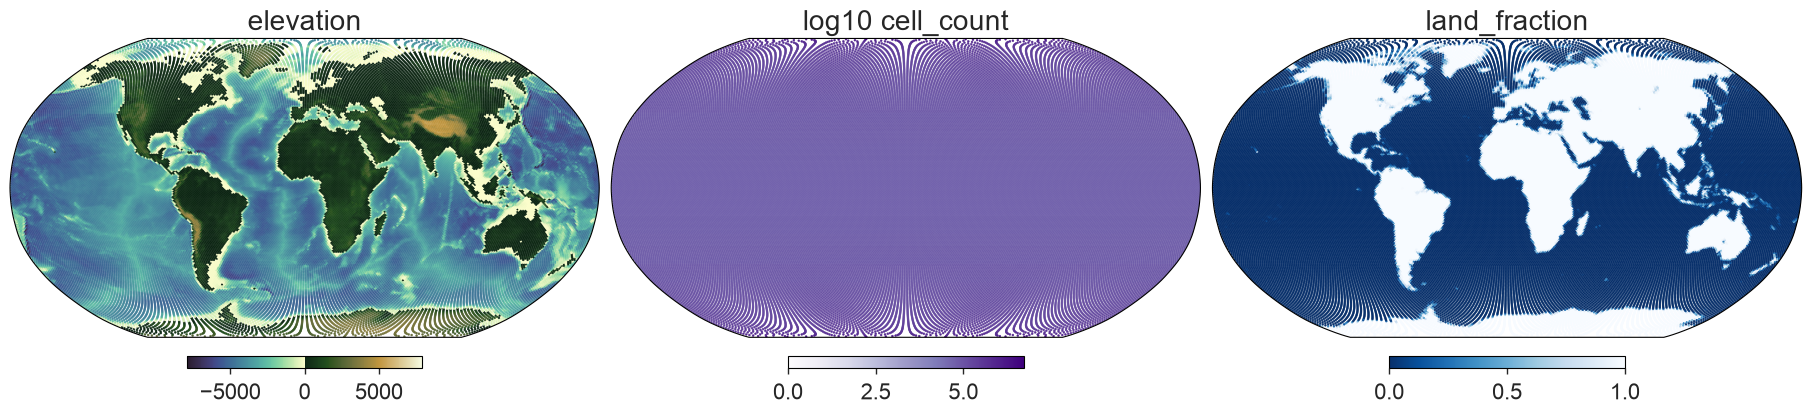

In [28]:
nrows=1
ncols=3
ntime = nrows*ncols
fig, axs = plt.subplots(nrows, ncols, figsize=(6*ncols,4*nrows), subplot_kw={"projection": ccrs.Robinson()})

for name, cmap, log, ax in zip(
    ["elevation","cell_count","land_fraction"],
    ["cmo.topo", "Purples", "Blues_r"],
    [False, True, False],
    axs):
    p = ax.scatter(
        ds.longitude,
        ds.latitude,
        c=ds[name] if not log else np.log10(ds[name]),
        cmap=cmap,
        vmin=ds[name].min().values if name == "elevation" else 0,
        vmax=-ds[name].min().values if name == "elevation" else None,
        s=2,
        transform=ccrs.PlateCarree(),
    )
    ax.set(title=name if not log else f"log10 {name}")
    plt.colorbar(p, ax=ax, orientation="horizontal", shrink=.4)
    #ax.set_extent((-180, 180, 45, 90), crs=ccrs.PlateCarree())
fig.savefig(f"{fig_dir}/elevation_robinson_hpx6.jpeg", dpi=300, bbox_inches="tight")

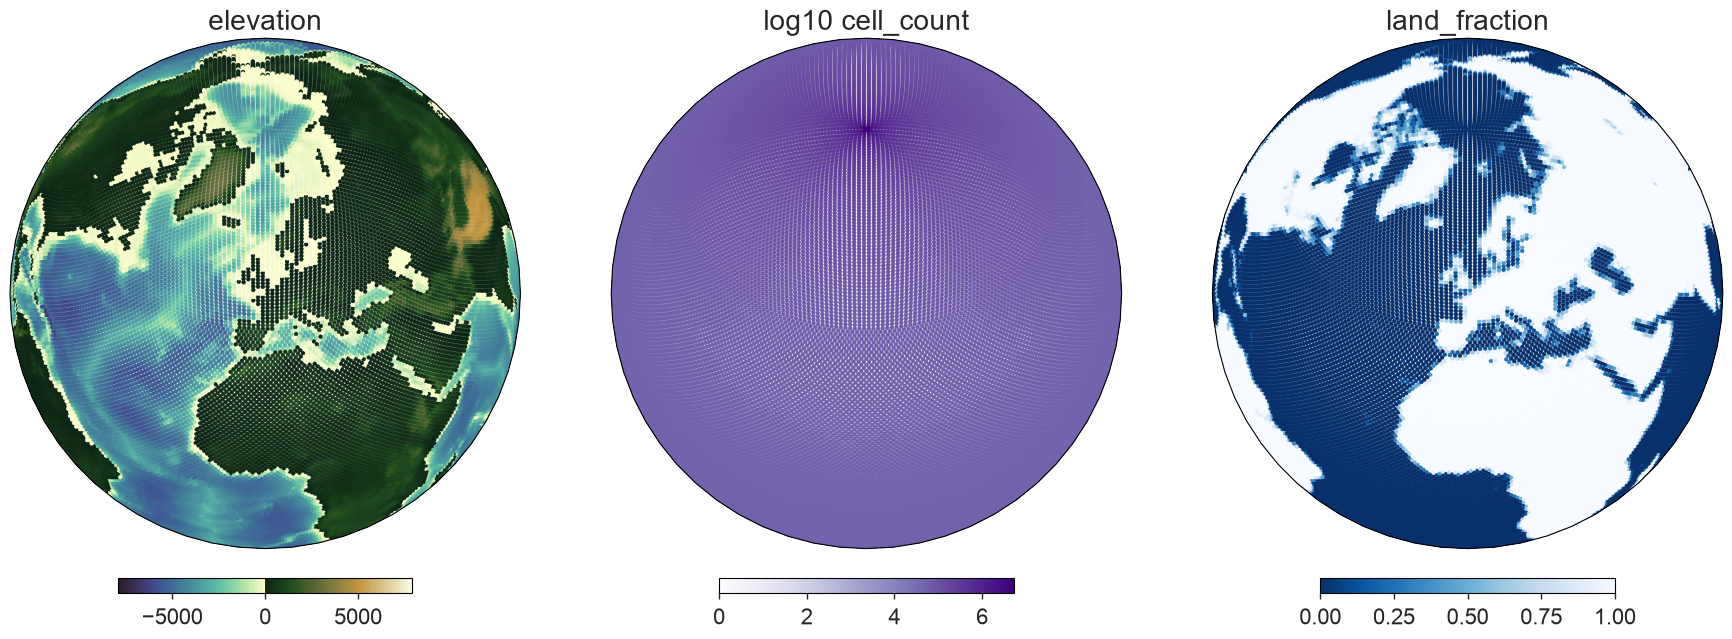

In [29]:
nrows=1
ncols=3
ntime = nrows*ncols
fig, axs = plt.subplots(nrows, ncols, figsize=(6*ncols,6.25*nrows), subplot_kw={"projection": ccrs.Orthographic(0, 50)})

for name, cmap, log, ax in zip(
    ["elevation","cell_count","land_fraction"],
    ["cmo.topo", "Purples", "Blues_r"],
    [False, True, False],
    axs):
    p = ax.scatter(
        ds.longitude,
        ds.latitude,
        c=ds[name] if not log else np.log10(ds[name]),
        cmap=cmap,
        vmin=ds[name].min().values if name == "elevation" else 0,
        vmax=-ds[name].min().values if name == "elevation" else None,
        s=8,
        transform=ccrs.PlateCarree(),
    )
    ax.set(title=name if not log else f"log10 {name}")
    plt.colorbar(p, ax=ax, orientation="horizontal", shrink=.5)
    #ax.set_extent((-180, 180, 45, 90), crs=ccrs.PlateCarree())
fig.savefig(f"{fig_dir}/elevation_orthonordic_hpx6.jpeg", dpi=300, bbox_inches="tight")

In [31]:
ds.land_fraction.where(ds.land_fraction>0).min().values

array(4.72355e-06, dtype=float32)

In [15]:
ads = xr.open_dataset("../experimental/local-sla-only/gebco-anemoi-hpx6/dataset.zarr/")

In [16]:
ads.attrs["variables"]

['elevation', 'land_fraction']

In [19]:
ads.attrs

{'allow_nans': True,
 'area_check_max': 1.00117641972384,
 'area_check_min': 0.9992095208373832,
 'binned': True,
 'constant_fields': ['elevation', 'land_fraction'],
 'end_date': '2001-12-31T00:00:00',
 'ensemble_dimension': 1,
 'field_shape': [49152],
 'flatten_grid': True,
 'frequency': '24h',
 'healpix_level': 6,
 'healpix_nside': 64,
 'healpix_ordering': 'nested',
 'latest_write_timestamp': '2026-08-07T14:57:10',
 'missing_dates': [],
 'name_to_index': {'elevation': 0, 'land_fraction': 1},
 'regrid_method': 'conservative',
 'resolution': 'healpix_6',
 'source_cells_per_target_cell': 75937.5,
 'source_grid_shape': '43200x86400',
 'start_date': '2000-01-01T00:00:00',
 'variables': ['elevation', 'land_fraction'],
 'variables_metadata': {'elevation': {'group': None,
   'param': 'elevation',
   'source': 'GEBCO'},
  'land_fraction': {'group': None,
   'param': 'land_fraction',
   'source': 'GEBCO'}}}

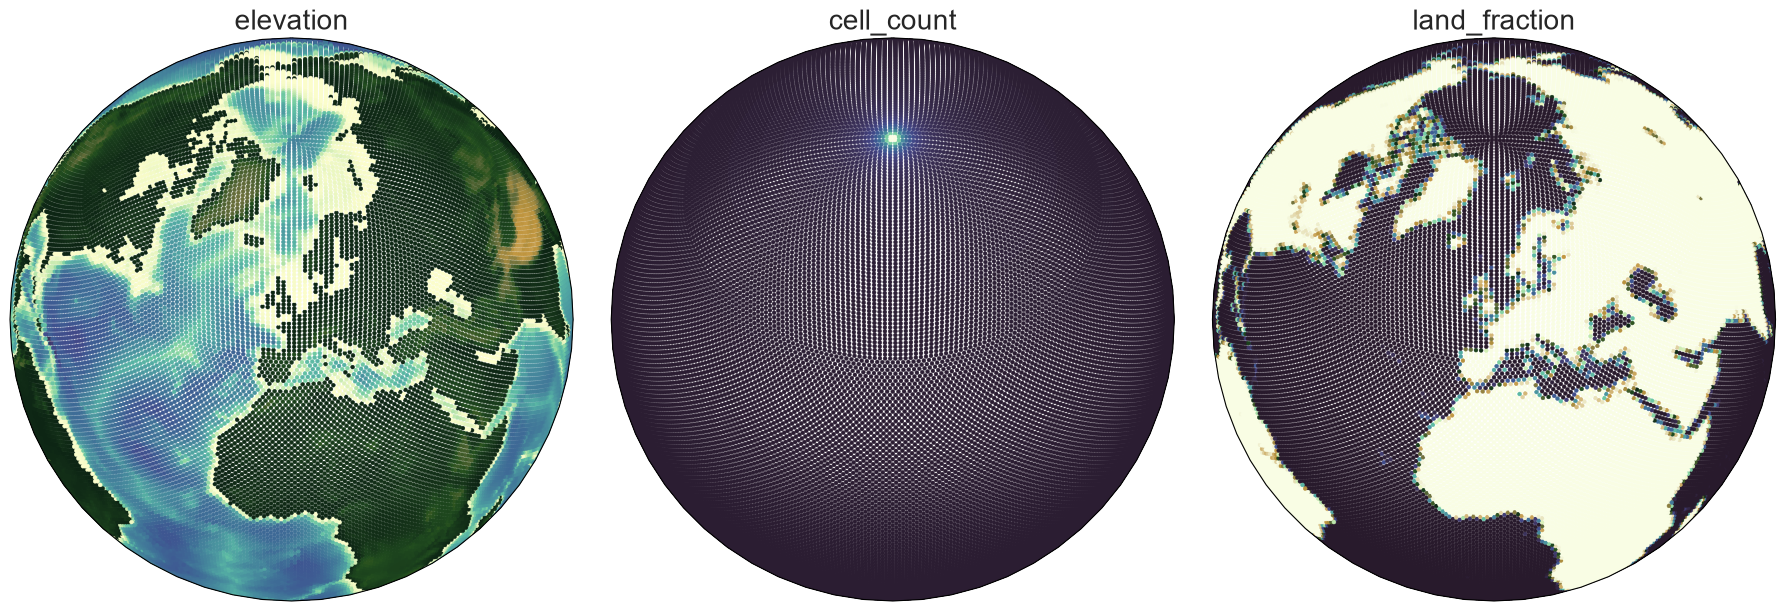

In [20]:
nrows=1
ncols=3
ntime = nrows*ncols
fig, axs = plt.subplots(nrows, ncols, figsize=(6*ncols,6*nrows), subplot_kw={"projection": ccrs.Orthographic(0, 50)})

for name, ax in zip(["elevation","cell_count","land_fraction"], axs):
    plotme = ads[name] if name == "cell_count" else ads["data"].isel(time=0, variable=ads.attrs["name_to_index"][name])
    ax.scatter(
        ads.longitudes,
        ads.latitudes,
        c=plotme,
        cmap="cmo.topo",
        vmin=plotme.min().values if name == "elevation" else 0,
        vmax=-plotme.min().values if name == "elevation" else None,
        s=8,
        transform=ccrs.PlateCarree(),
    )
    ax.set(title=name)
    #ax.set_extent((-180, 180, 45, 90), crs=ccrs.PlateCarree())